# Collection, data types, data quality, and sampling

Phase I of *Prishtina Taxi Mobility*: what we received, in what shape, how good it is, and how to take a smaller piece of it that still represents the whole.

This notebook only reads what the pipeline wrote (`python -m taxi.pipeline run`, see the README). Every number below comes from those outputs, so the notebook and the tables in `reports/` cannot disagree.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from taxi import config, io

# Outputs of a --dev run instead of the full run (for testing the notebook only).
DEV = os.environ.get("TAXI_NOTEBOOK_DEV") == "1"
config.set_dev(DEV)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)


def figure(name):
    display(Image(filename=str(config.figures_dir() / f"{name}.png"), width=900))


def table(name):
    path = io.report_table_path(name)
    if not path.exists():
        print(
            f"{path.relative_to(ROOT)} does not exist yet: run the stage that writes it."
        )
        return None
    return pd.read_csv(path)


print("Reading the outputs of the", "dev run" if DEV else "full run")

Reading the outputs of the full run


## 1. Data collection

**Source.** Kadri Sylejmani, *Movement of taxi vehicles in Prishtina*, Kaggle, version 1 (last updated 2025-02-24), MIT licence. GPS traces of taxis in Prishtina from June 1 to August 31, 2023, one CSV file per vehicle, named by the vehicle's id. The dataset author told us what the three digital inputs mean: `Di1` is the ignition, `Di2` the taximeter, and `Di3` passenger presence (the last two from memory). He could not confirm whether `DeviceDateTime` is UTC or local time; we treat it as local time (UTC+2 in the whole period).

**Pinning the input.** `verify-raw` writes one row per raw file with its size, row count, header, first and last timestamp, and SHA-256. Every later run compares the files against this inventory and stops on any difference, so everyone works from the same bytes.

In [2]:
inventory = pd.read_csv(config.RAW_INVENTORY_CSV)
small = (inventory["bytes"] > 0) & (inventory["bytes"] < config.SMALL_FILE_BYTES)
print(
    f"{len(inventory)} files, {(inventory['bytes'] > 0).sum()} with data, "
    f"{inventory['rows'].sum():,} data rows, {inventory['bytes'].sum() / 1e9:.2f} GB"
)
print("Empty files:", ", ".join(inventory.loc[inventory["bytes"] == 0, "file"]))
print("Files under 2 MB:", ", ".join(inventory.loc[small, "file"]))
inventory.sort_values("rows").head(8)

85 files, 83 with data, 28,590,588 data rows, 2.28 GB
Empty files: 8.csv, 27.csv
Files under 2 MB: 18.csv, 36.csv, 64.csv, 66.csv


,file,vehicle_id,bytes,rows,header,first_ts_raw,last_ts_raw,sha256
23,27.csv,27,0,0,NaN,NaN,NaN,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
7,8.csv,8,0,0,NaN,NaN,NaN,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
59,66.csv,66,324663,3982,"DeviceDateTime,Longitute,Latitude,Speed,Direction,Di1,Di2,Di3",6/10/2023 9:16:11 AM,8/24/2023 1:14:49 PM,1a29113e6abcaff3562fb9b026e7576f25463d5bce93bf1be6aa914d7725925f
57,64.csv,64,380927,4676,"DeviceDateTime,Longitute,Latitude,Speed,Direction,Di1,Di2,Di3",6/1/2023 12:01:01 AM,7/18/2023 6:59:32 AM,82b41de485d20ad363c7ca6d23df0d451768238c572c6e53441be743d63b28c5
32,36.csv,36,819051,10157,"DeviceDateTime,Longitute,Latitude,Speed,Direction,Di1,Di2,Di3",6/1/2023 12:02:01 AM,6/22/2023 11:48:56 AM,2e2f390dbc22f68b4b349b7ed4c250d2eae798a4e747e75ec2d9f4463da1f402
14,18.csv,18,1696089,21098,"DeviceDateTime,Longitute,Latitude,Speed,Direction,Di1,Di2,Di3",6/2/2023 8:58:57 AM,6/25/2023 6:41:05 PM,79d9a2bc5180fd15db2de028d6e206e4069e20d2e1cc180dc7368a05673e561a
12,16.csv,16,3108133,38571,"DeviceDateTime,Longitute,Latitude,Speed,Direction,Di1,Di2,Di3",6/1/2023 12:05:40 AM,6/27/2023 11:22:38 AM,b25cd2f2b8681e949672240554006573e77f0029f27246da3ca699eaff01225a
28,32.csv,32,6666678,83225,"DeviceDateTime,Longitute,Latitude,Speed,Direction,Di1,Di2,Di3",6/1/2023 12:04:53 AM,7/22/2023 12:23:36 PM,5e70cc8ec83fdebf2215370b2b0b1788e2eee1842dd8d641f687563128a32302


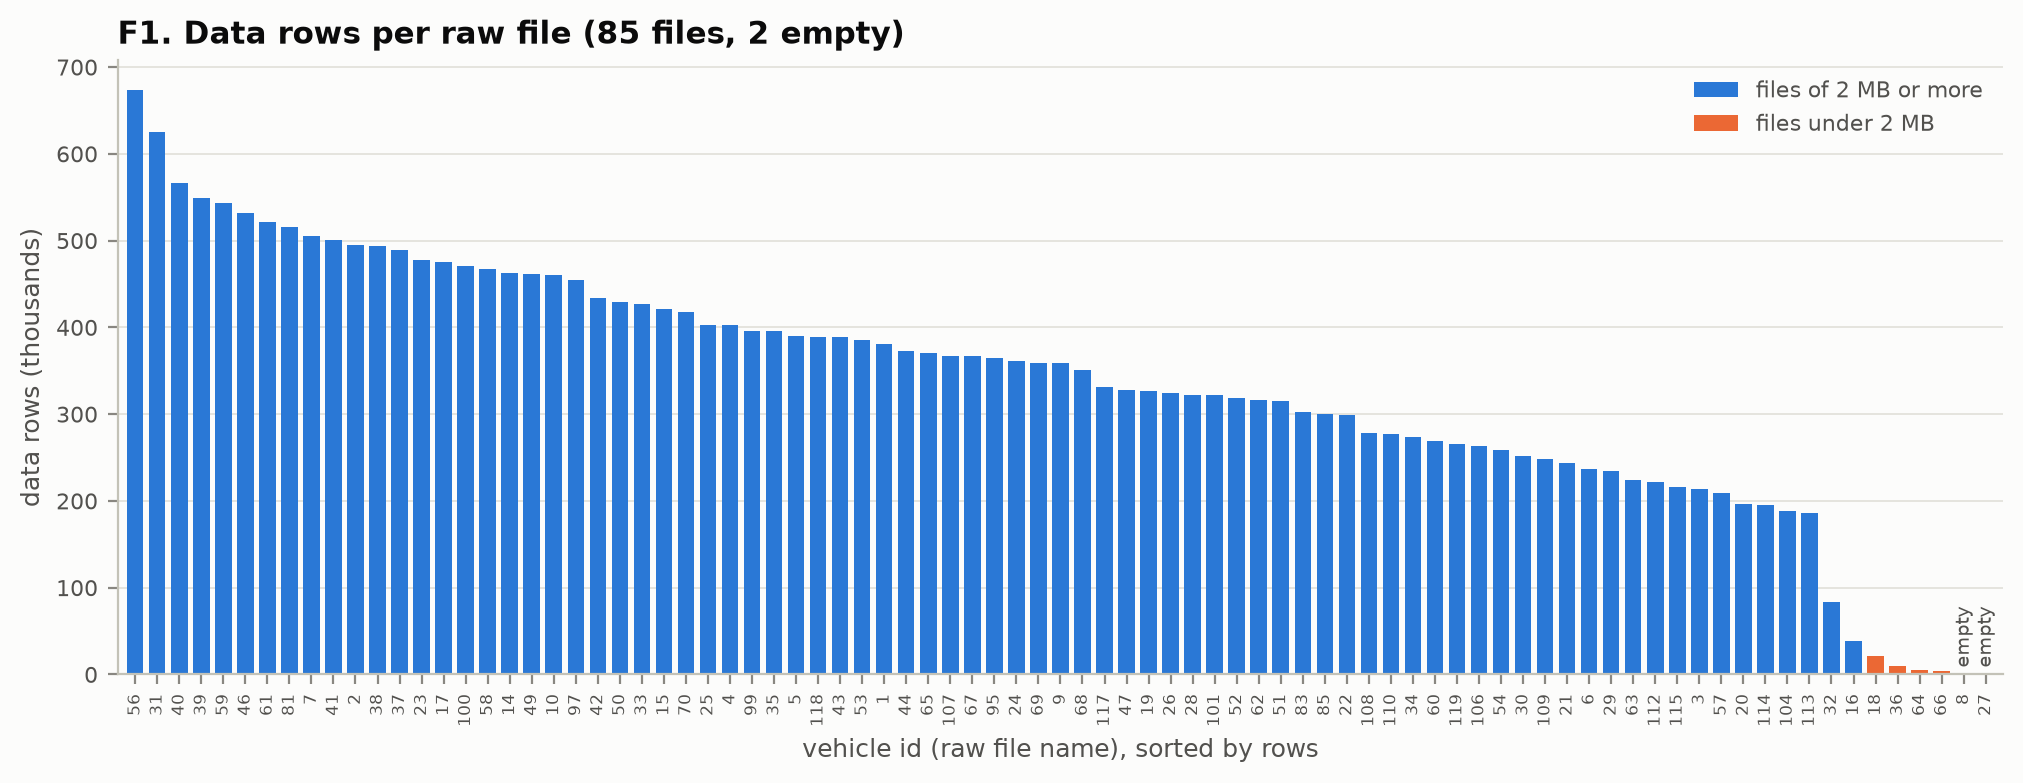

In [3]:
figure("f01_rows_per_vehicle")

### What the raw text looks like

Every file has the header `DeviceDateTime, Longitute (sic), Latitude, Speed, Direction, Di1, Di2, Di3`. Most files quote every field and write booleans as `True`/`False`, with timestamps like `6/1/2023 12:02:57 AM` (month first, 12-hour clock, with seconds).

Two files, `1.csv` and `100.csv`, were re-saved in a spreadsheet with a day-first locale. For days 1 to 12 of each month their timestamps became `06/01/2023 00:05`: the spreadsheet read those values as dates and wrote them back without seconds. For days 13 to 31 the text could not be read as a date and stayed as it was. The same files also lost their quotes and write `TRUE`/`FALSE`.

In [4]:
from itertools import islice

for vehicle, rows in [(2, [0, 1]), (1, [0, 1, 47588])]:
    with io.raw_path(vehicle).open(encoding="utf-8") as fh:
        lines = [line.rstrip() for line in islice(fh, max(rows) + 2)]
    print(f"{vehicle}.csv")
    print("  header   :", lines[0])
    for r in rows:
        print(f"  row {r:>6}:", lines[r + 1])

2.csv
  header   : "DeviceDateTime","Longitute","Latitude","Speed","Direction","Di1","Di2","Di3"
  row      0: "6/1/2023 12:02:57 AM","21.138603","42.673818","0","344","False","False","False"
  row      1: "6/1/2023 12:08:48 AM","21.138603","42.673818","0","344","False","False","False"
1.csv
  header   : DeviceDateTime,Longitute,Latitude,Speed,Direction,Di1,Di2,Di3
  row      0: 06/01/2023 00:05,21.139287,42.673653,0,16,FALSE,FALSE,TRUE
  row      1: 06/01/2023 00:11,21.139287,42.673653,0,16,FALSE,FALSE,TRUE
  row  47588: 6/13/2023 12:02:35 AM,21.139057,42.673647,0,148,FALSE,FALSE,TRUE


## 2. Data types

`ingest` reads every column as text and converts it with an explicit format, never letting pandas guess. Timestamps are parsed with the two formats above and must all succeed; booleans are mapped from the exact strings found (`True`, `False`, `TRUE`, `FALSE`), because `astype(bool)` would turn every non-empty string, including `"FALSE"`, into True. Nothing is dropped here: a value that does not parse becomes NA and is counted.

The attribute type says which operations make sense. `vehicle_id` is stored as a number but is nominal: averaging ids means nothing. Timestamps are interval: differences make sense, ratios do not. Speed is ratio: 0 means standing still and 60 km/h is twice 30 km/h. The heading is interval and circular: the mean of 350 and 10 degrees is 0, not 180. The digital inputs are binary.

In [5]:
dictionary = io.read_dictionary()
dictionary[dictionary["dataset"] == "interim/points"][
    ["column", "dtype", "unit", "attribute_type", "description", "source"]
]

,column,dtype,unit,attribute_type,description,source
0,vehicle_id,int16,,nominal,"Taxi id, from the raw file name. Stored as a number, but only a label.",file name
1,source_row,int32,,ordinal,0-based data row in the raw file. With vehicle_id it points back to one raw line.,row position in the raw file
2,ts_utc,"datetime64[ns, UTC]",,interval,"Time of the point in UTC, used for storage, ordering, and time differences. Difference...","DeviceDateTime, read on the device clock (DEVICE_TZ)"
3,ts_local,"datetime64[ns, Europe/Skopje]",,interval,"The same instant in Kosovo local time, used for everything calendar-related (date, hou...",ts_utc
4,ts_has_seconds,boolean,,nominal,False when the raw timestamp has minutes only: vehicles 1 and 100 on days 1-12 of each...,format of DeviceDateTime
5,lon,float64,degrees (WGS 84),interval,Longitude.,Longitute (sic)
6,lat,float64,degrees (WGS 84),interval,Latitude.,Latitude
7,speed_kmh,float32,km/h,ratio,"Speed reported by the device. 0 means standing still and 60 km/h is twice 30 km/h, so ...",Speed
8,heading_deg,float32,degrees,"interval, circular","Direction of travel. Circular: the mean of 350 and 10 degrees is 0, not 180.",Direction
9,di1,boolean,,nominal,"Digital input 1, binary: the ignition is on (dataset author).",Di1


In [6]:
summary = table("ingest_summary")
if summary is not None:
    totals = summary.drop(columns="vehicle_id").sum()
    print(
        f"{totals['rows']:,} rows: {totals['ts_with_seconds']:,} timestamps with seconds, "
        f"{totals['ts_minutes_only']:,} with minutes only, {totals['ts_unparsed']:,} unparsed, "
        f"{totals['ts_outside_window']:,} outside the study window"
    )
    unparsed = totals[[c for c in totals.index if c.endswith("_unparsed")]]
    empty = totals[[c for c in totals.index if c.endswith("_empty")]]
    print("Values that did not parse:", unparsed[unparsed > 0].to_dict() or "none")
    print("Empty fields in the raw files:", empty[empty > 0].to_dict() or "none")

28,590,588 rows: 28,268,982 timestamps with seconds, 321,606 with minutes only, 0 unparsed, 0 outside the study window
Values that did not parse: none
Empty fields in the raw files: {'di2_empty': 4, 'di3_empty': 4}


**Memory.** The same vehicle's data as a CSV file, as pandas reads it when it guesses the types, with our explicit types, and as Parquet on disk. The typed table has more columns but needs about half the memory, mostly because pandas keeps a timestamp it cannot guess as a Python string, while the typed table stores it as a 64-bit number.

In [7]:
table("dtypes_memory")[["vehicle_id", "rows", "representation", "mb", "dtypes"]]

,vehicle_id,rows,representation,mb,dtypes
0,56,674089,CSV file on disk,54.30,text
1,56,674089,"pandas, read_csv with guessed dtypes",70.08,"DeviceDateTime: object, Longitute: float64, Latitude: float64, Speed: int64, Direction..."
2,56,674089,"pandas, typed interim schema",36.40,"vehicle_id: int16, source_row: int32, ts_utc: datetime64[ns, UTC], ts_local: datetime6..."
3,56,674089,Parquet file on disk (interim),18.16,"typed interim schema, snappy compression"


## 3. Data quality

The profile checks every vehicle along six dimensions: **completeness** (missing values, vehicle-days without data), **validity** (values outside their possible range, values that did not parse), **uniqueness** (duplicate rows, several rows at the same time), **consistency** (the inputs against each other, and the reported speed against the speed implied by distance and time), **timeliness** (the time between points), and **plausibility** (points outside Kosovo, which can be real trips abroad). Before cleaning the outside-Kosovo check uses the bounding box of the Who's On First Kosovo polygon; after cleaning it uses the polygon itself.

In [8]:
before = table("quality_before")
counts = before[before["value"].isna()]
shown = counts[(counts["check"] != "missing values") | (counts["count"] > 0)]
shown[["dimension", "check", "column", "n", "count", "share"]]

,dimension,check,column,n,count,share
10,completeness,missing values,di2,28590588,4.0,0.000000
11,completeness,missing values,di3,28590588,4.0,0.000000
12,completeness,vehicle-days without any point,ts_local,7636,1117.0,0.146281
13,validity,outside the study window,ts_utc,28590588,0.0,0.000000
14,validity,outside -90 to 90,lat,28590588,0.0,0.000000
15,validity,outside -180 to 180,lon,28590588,0.0,0.000000
16,validity,latitude and longitude both 0,"lat, lon",28590588,0.0,0.000000
17,validity,below 0 or above 200 km/h,speed_kmh,28590588,0.0,0.000000
18,validity,outside 0 to 360,heading_deg,28590588,0.0,0.000000
19,uniqueness,exact duplicate of an earlier row (timestamp with seconds),all raw fields,28268982,73676.0,0.002606


The duplicate checks are split by timestamp resolution. Where the seconds were lost, a parked taxi that reports every 10 seconds produces rows that look identical within a minute although they are separate readings. Rows with seconds show how many true duplicates the devices sent.

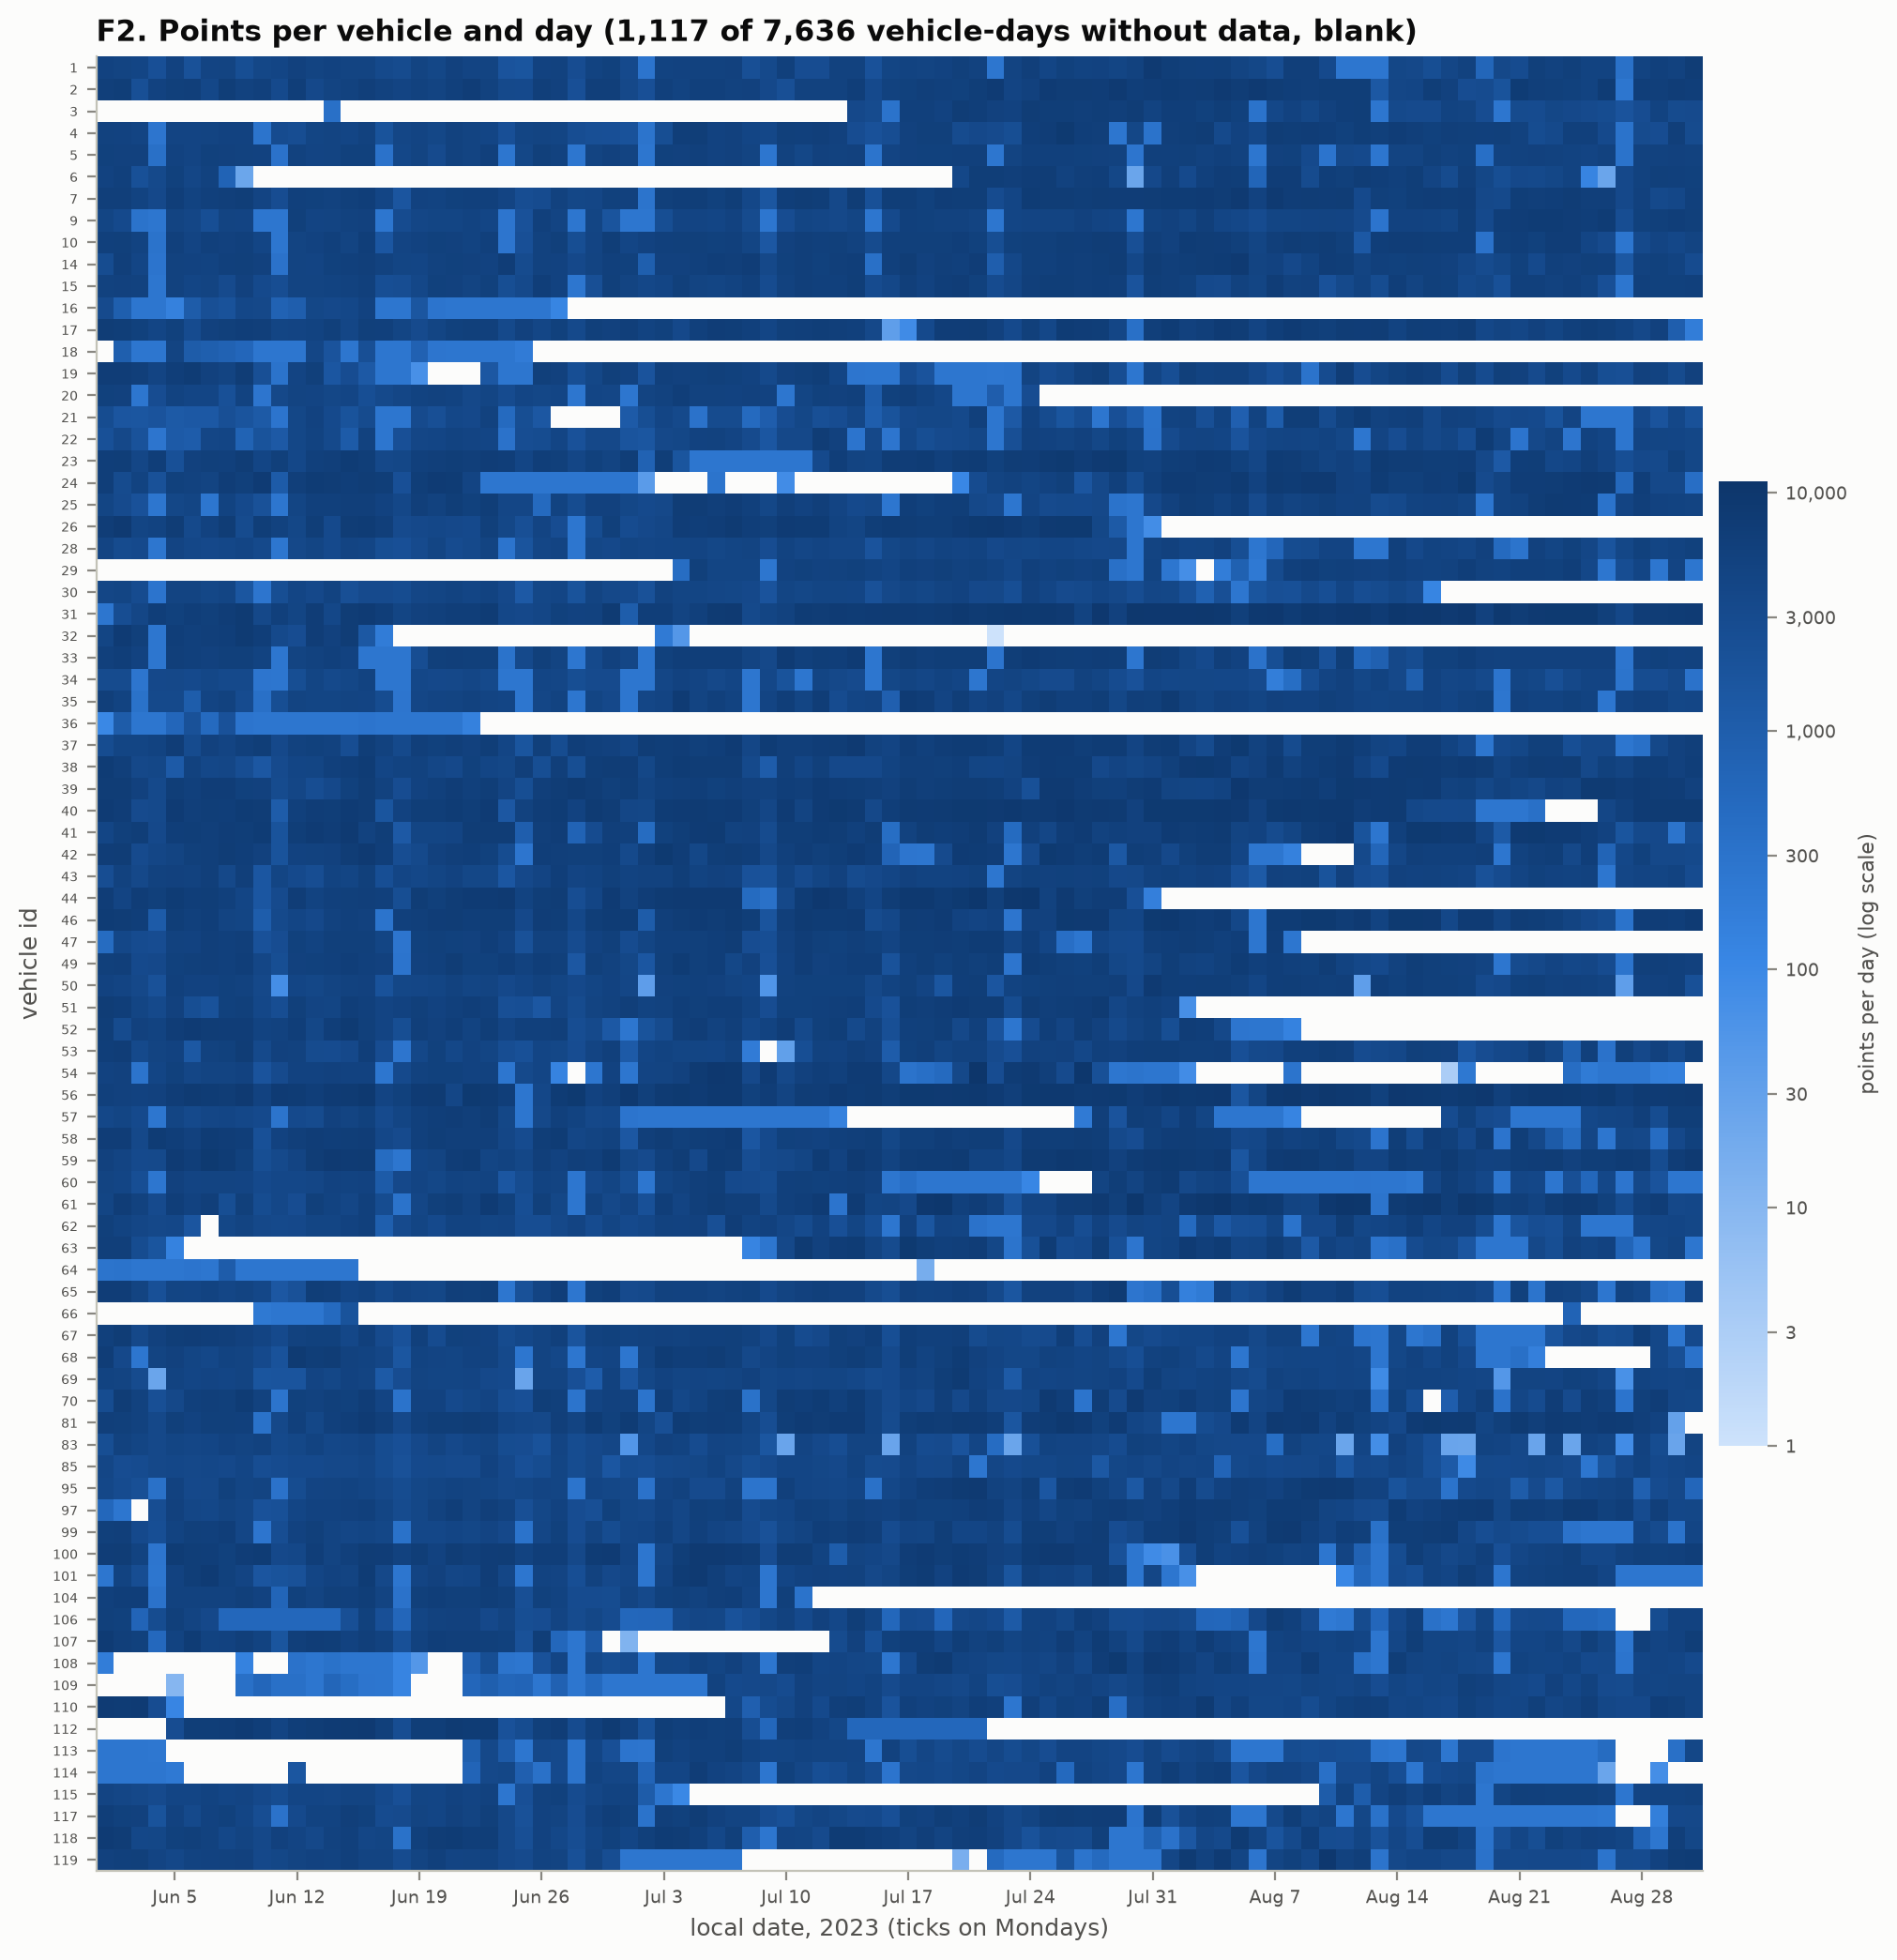

In [9]:
figure("f02_coverage_vehicle_day")

### When does a device send a point?

The dataset does not document it, so we read it from the data. The state of an interval is the state of the point it starts at: moving (speed of at least 5 km/h), standing with the ignition on, or ignition off.

In [10]:
values = before[before["value"].notna()]
timeliness = values[values["dimension"] == "timeliness"]
timeliness.pivot_table(
    index="column", columns="check", values="value", sort=False
).round(2)

check,"interval to next point, p10","interval to next point, p50","interval to next point, p90","interval to next point, p99",share of observed time (steps up to GAP_S)
column,,,,,
all,4.0,10.0,10.0,351.0,NaN
moving,3.0,10.0,10.0,11.0,0.28
"standing, ignition on",4.0,10.0,10.0,11.0,0.17
ignition off,76.0,350.0,351.0,360.0,0.55


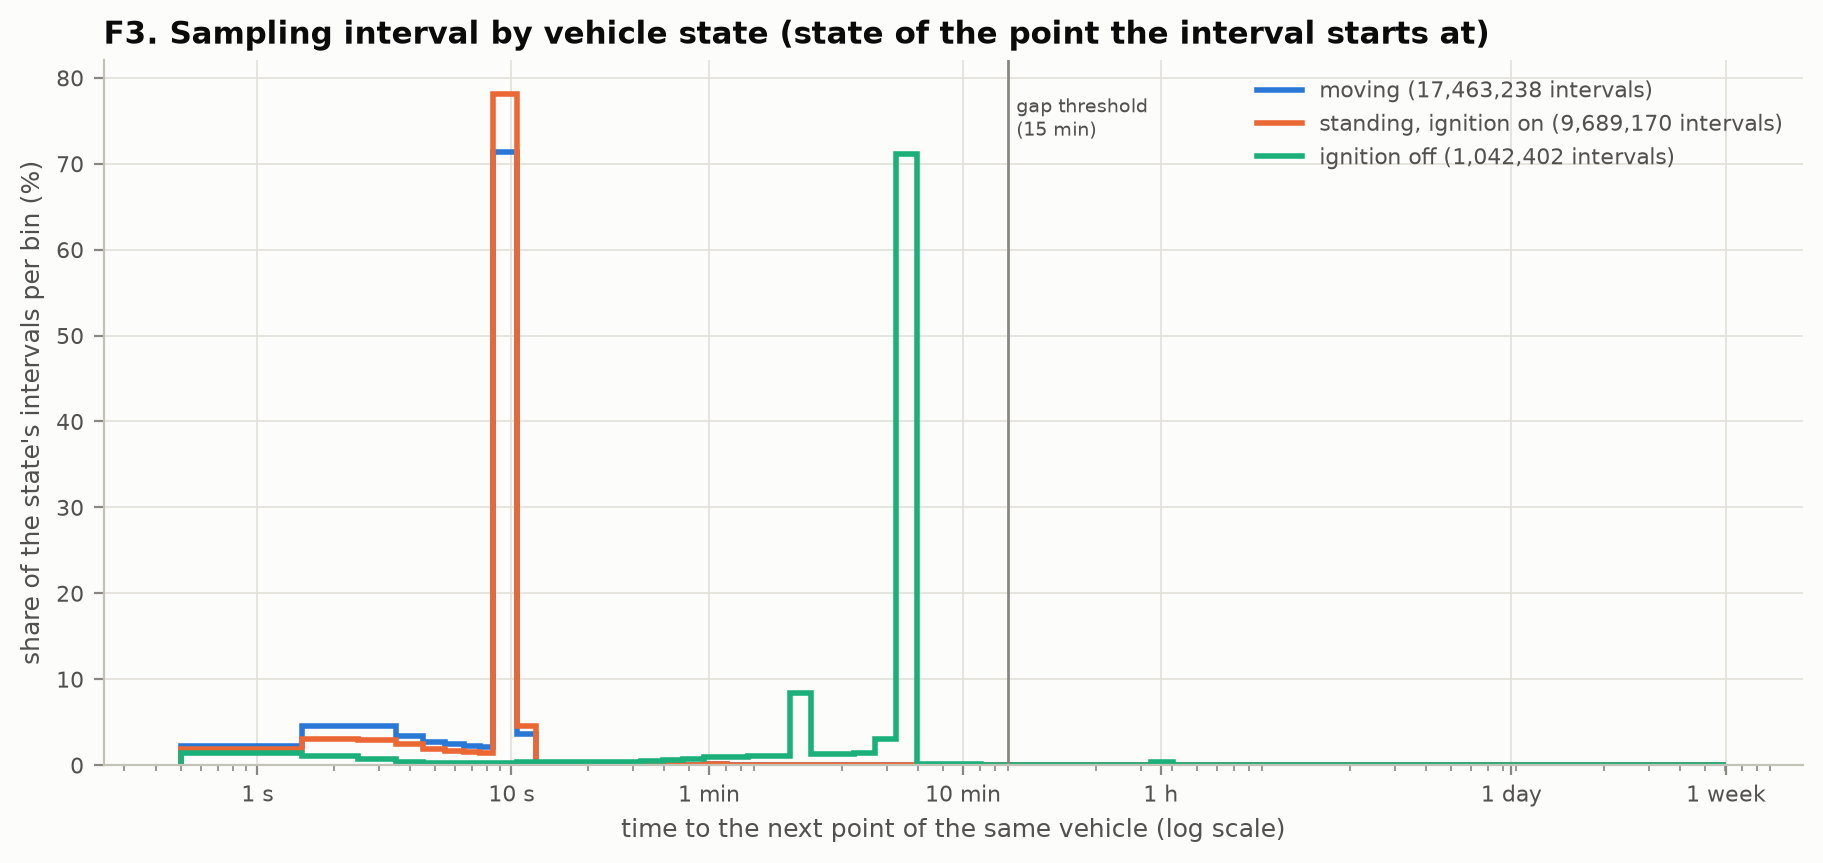

In [11]:
figure("f03_sampling_interval")

In [12]:
values[values["dimension"] == "consistency"][["check", "n", "value", "unit"]]

,check,n,value,unit
57,"reported / implied speed, median",14077341,0.985257,ratio
58,"absolute difference, median",14077341,4.824967,km/h
59,"absolute difference, p90",14077341,14.680534,km/h


The reported speed matches the speed implied by consecutive positions (compared on 5 to 60 second steps of at least 10 m, where GPS jitter matters less), which confirms the unit, km/h.

### Before and after cleaning

In [13]:
after = table("quality_after")
if after is not None:
    keys = ["dimension", "check", "column"]
    side = before[before["value"].isna()].merge(
        after[after["value"].isna()],
        on=keys,
        how="outer",
        suffixes=(" before", " after"),
    )
    changed = side[side["count before"].fillna(0) != side["count after"].fillna(0)]
    display(changed[keys + ["n before", "count before", "n after", "count after"]])

reports/tables/quality_after.csv does not exist yet: run the stage that writes it.


## 4. Sampling

Four methods, all with seed 42, drawn from the cleaned points: a simple random sample of 1%, a stratified sample with the same fraction from every vehicle and hour of day (at least one row per stratum), a systematic sample with one point per vehicle per minute, and a cluster sample with all points of 10 random vehicles. The stratified sample is repeated at growing sizes (progressive sampling) to see where the comparison with the full data stops improving.

In [14]:
evaluation = table("sampling_evaluation")
if evaluation is not None:
    display(evaluation)
    figure("f08_samples_vs_full")

reports/tables/sampling_evaluation.csv does not exist yet: run the stage that writes it.


The systematic sample is not a smaller copy of the points: thinning to one point per minute keeps every point of a parked taxi (which reports every 6 minutes) but only one in six of a moving one. It behaves like a sample over time rather than over points, which shows in its lower moving share.